# SmartCommerce AI – Online Shopping Purchase Prediction
## Classification Track
### Objective
The objective of this classification task is to predict whether an online shopping session will result in a purchase.
The target variable is `Revenue`, where:
- `False` represents a session that did not result in a purchase.
- `True` represents a session that resulted in a purchase.
Five Part-A classification algorithms required for Review 1 are implemented:
1. Logistic Regression
2. K-Nearest Neighbors
3. Gaussian Naive Bayes
4. Decision Tree Classifier
5. Support Vector Machine

In [ ]:
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

from sklearn.model_selection import GridSearchCV

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

## 2.Load the Dataset
The Online Shoppers Purchasing Intention dataset is loaded using Pandas.
The dataset contains information about users' online shopping sessions, including browsing activity, visitor information, traffic information, and other session-related attributes.
The target variable for this classification problem is `Revenue`.

In [ ]:
df = pd.read_csv("online_shoppers_intention.csv")
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 3. Initial Dataset Audit
Before performing preprocessing or model training, the dataset must be inspected.
The following properties are checked:
- Number of rows and columns
- Data types
- Missing values
- Target-class distribution
This initial audit helps us understand the structure and quality of the dataset before applying machine-learning algorithms.

In [ ]:
print("Dataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df["Revenue"].value_counts())

print("\nTarget Distribution (%):")
print(df["Revenue"].value_counts(normalize=True) * 100)

Dataset Shape: (12330, 18)

Data Types:
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
Revenue                       bool
dtype: object

Missing Values:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month    

### Dataset Audit – Observation

The dataset contains 12,330 observations and 18 columns.

The data types include numerical, categorical, and Boolean variables. The `Revenue` column is the target variable for the classification task.

The missing-value analysis is performed before preprocessing so that any missing observations can be handled appropriately.

The target distribution shows that the two classes are not equally represented. Therefore, class imbalance should be considered when interpreting classification performance, and accuracy should not be used as the only evaluation metric.

## 4. Duplicate Data Analysis
Duplicate records are checked because repeated identical observations can give certain patterns greater influence during model training.
The number of duplicate rows is calculated before deciding whether they should be removed.

In [ ]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 125


### Duplicate Treatment
The duplicate rows identified in the previous step are removed so that identical observations are not unnecessarily repeated during model training.

After removal, the index is reset and the new dataset shape is checked.

In [ ]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (12205, 18)


## 5. Missing Value Analysis

Missing values are checked again after duplicate removal.

If missing values were present, an appropriate imputation strategy such as median imputation for numerical variables or mode imputation for categorical variables could be considered.

In this dataset, the missing-value check determines whether such treatment is necessary.

In [ ]:
missing_values = df.isnull().sum()

print(missing_values)

print("\nTotal missing values:",
      missing_values.sum())

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

Total missing values: 0


## 6. Statistical Summary

Descriptive statistics are generated for the numerical variables.

This provides information about the count, mean, standard deviation, minimum, quartiles, and maximum values.

These statistics are useful for understanding the range and distribution of the numerical features and for identifying potentially unusual observations.

In [ ]:
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000
mean,2.338878,81.646331,0.508726,34.825454,32.045637,1206.982457,0.020370,0.041466,5.949574,0.061942,2.124211,2.357804,3.153298,4.073904
std,3.330436,177.491845,1.275617,141.424807,44.593649,1919.601400,0.045255,0.046163,18.653671,0.199666,0.906823,1.710114,2.402340,4.016654
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,8.000000,193.000000,0.000000,0.014231,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,9.000000,0.000000,0.000000,18.000000,608.942857,0.002899,0.025000,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,94.700000,0.000000,0.000000,38.000000,1477.154762,0.016667,0.048529,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


## 7. Target Variable Distribution

The target variable `Revenue` is analyzed to determine the number of purchasing and non-purchasing sessions.

This is important because an imbalanced target can affect how classification metrics should be interpreted.

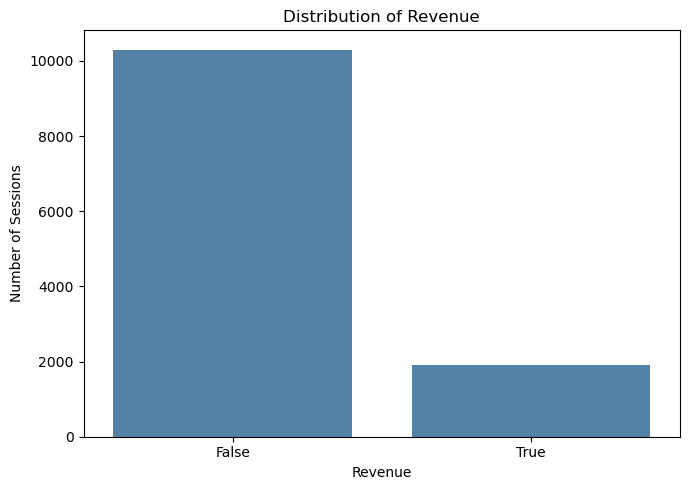

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Revenue", color="steelblue")

plt.title("Distribution of Revenue")
plt.xlabel("Revenue")
plt.ylabel("Number of Sessions")

plt.tight_layout()
plt.show()

### Observation

The target distribution shows that non-purchasing sessions are substantially more numerous than purchasing sessions. This indicates class imbalance in the target variable.

Because of this imbalance, model performance will be evaluated using multiple metrics rather than accuracy alone.

## 8. Numerical Feature Distributions

The distributions of numerical features are visualized using histograms with density curves.

These plots help identify the general shape of each feature's distribution, its range, and whether the feature contains highly concentrated or skewed values.

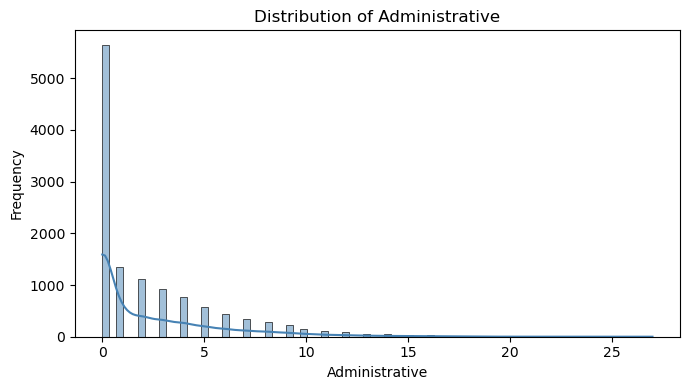

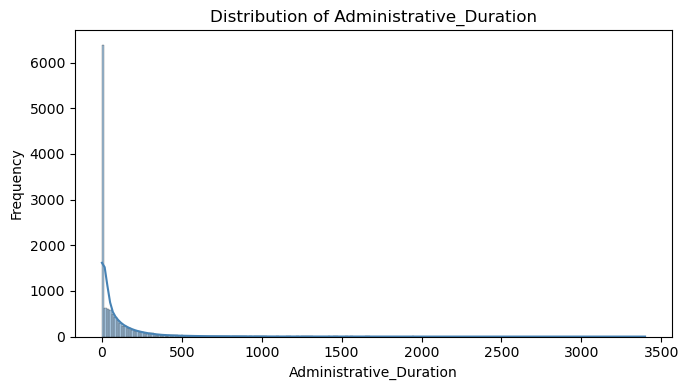

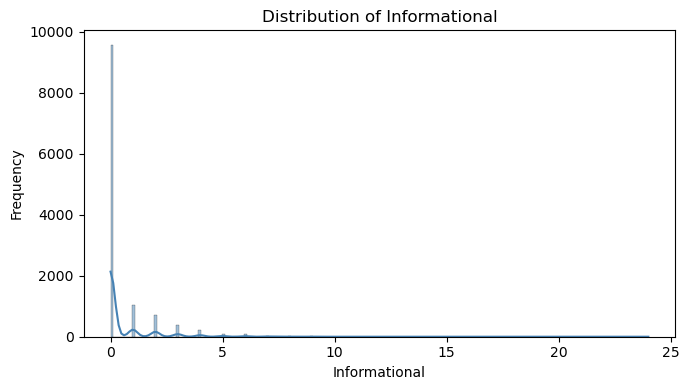

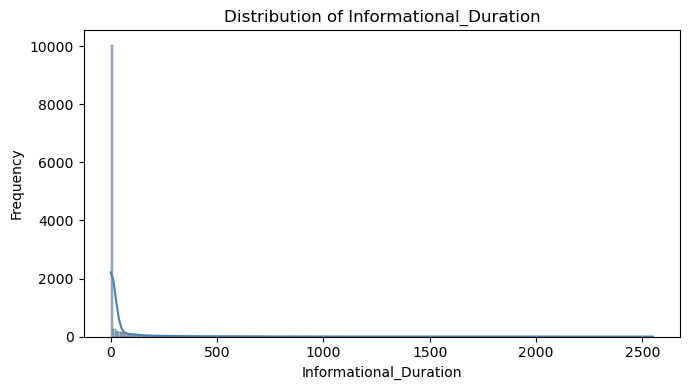

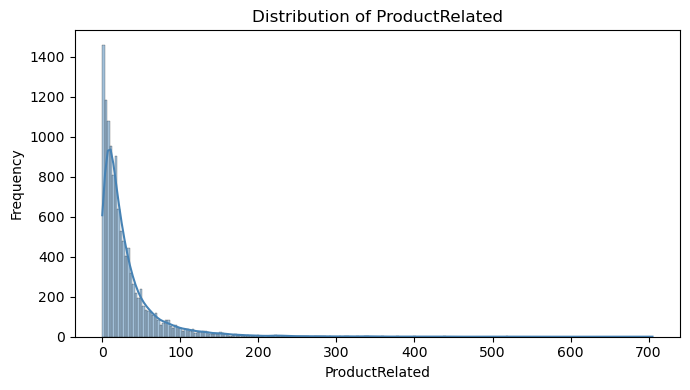

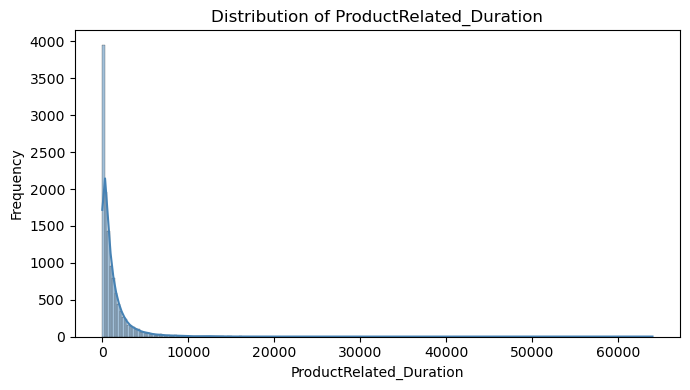

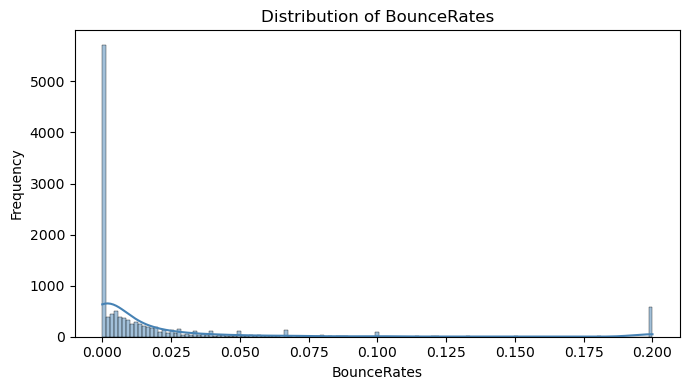

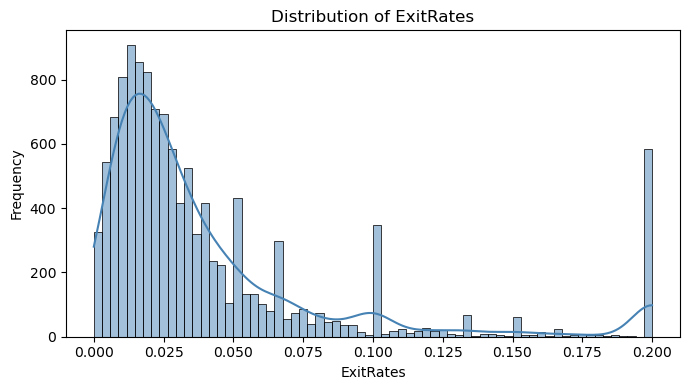

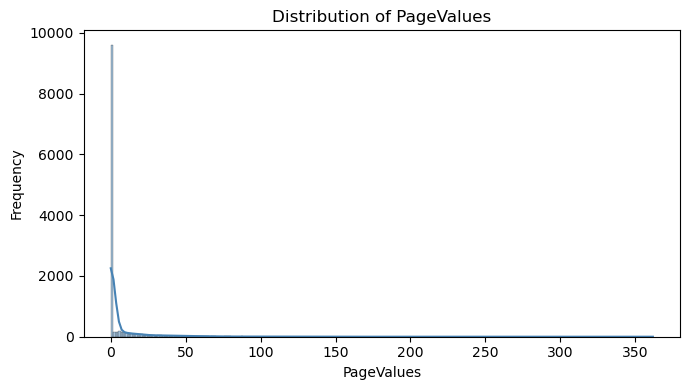

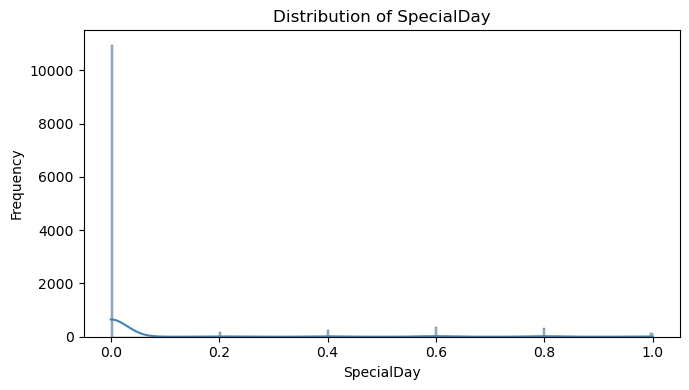

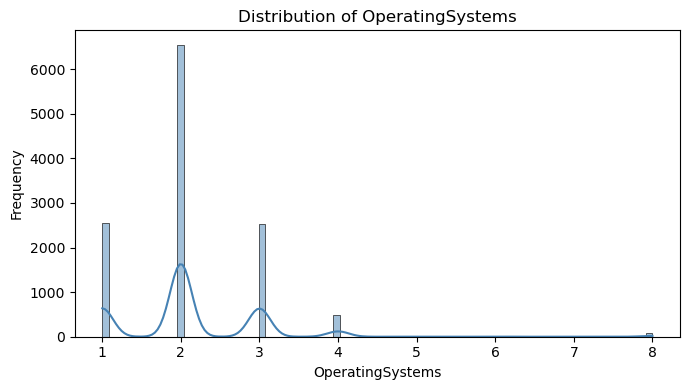

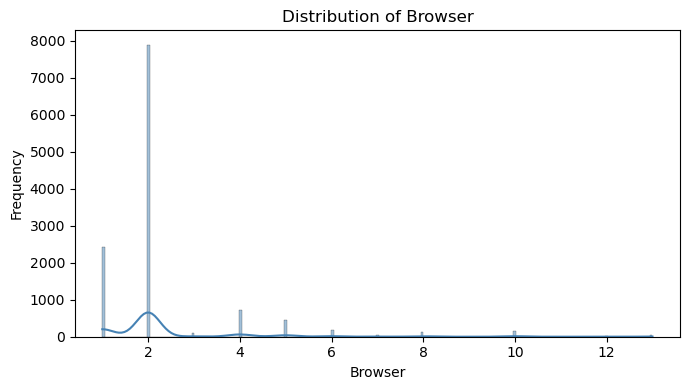

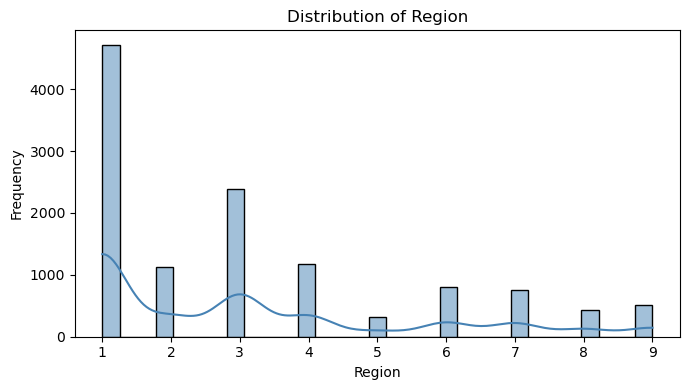

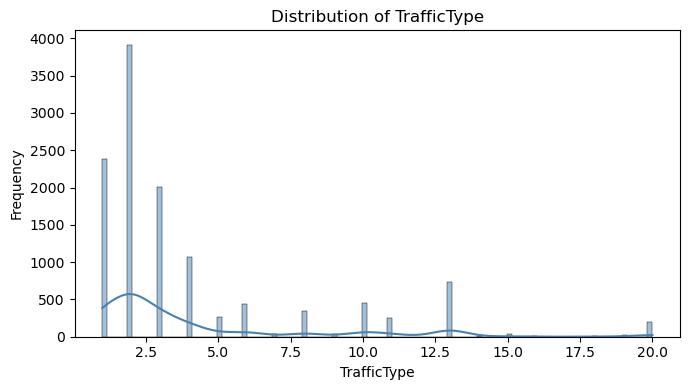

In [ ]:
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

for column in numerical_columns:
    plt.figure(figsize=(7, 4))
    
    sns.histplot(
        data=df,
        x=column,
        kde=True,
        color="steelblue"
    )
    
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    
    plt.tight_layout()
    plt.show()

### Distribution Plot Observations

The distribution plots were examined to understand the behaviour and spread of the numerical features.

Features with highly concentrated values or long tails were noted because such distributions may affect distance-based algorithms and can also indicate the presence of extreme observations.

The plots were also used as part of the preliminary outlier analysis.

## 9. Categorical Feature Analysis

Categorical variables cannot be directly used by most scikit-learn machine-learning algorithms in their original string form.

The distributions of the categorical variables are first visualized so that their categories and frequencies can be understood before encoding.

In [ ]:
categorical_columns = df.select_dtypes(
    include=["object", "bool"]
).columns

print("Categorical / Boolean columns:")
print(categorical_columns)

Categorical / Boolean columns:
Index(['Month', 'VisitorType', 'Weekend', 'Revenue'], dtype='object')


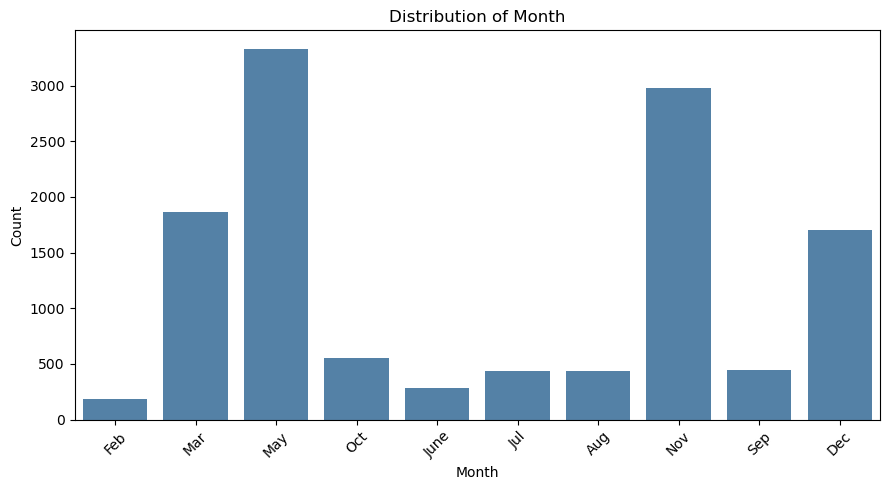

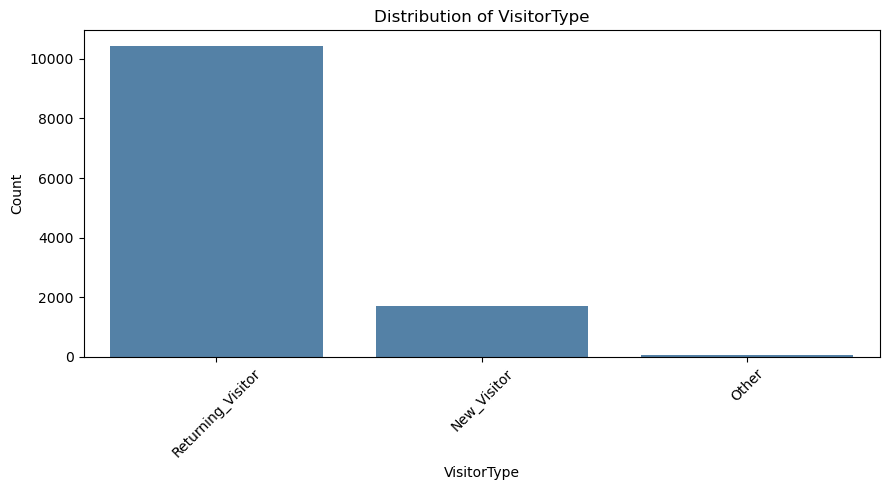

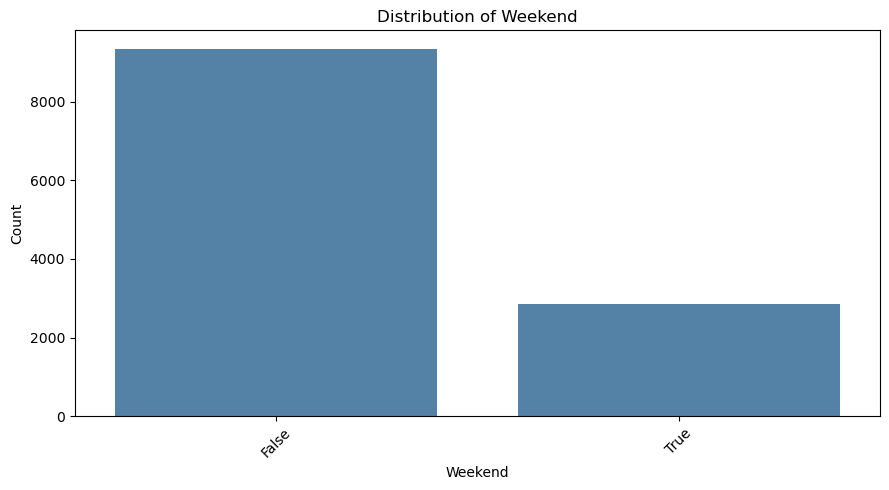

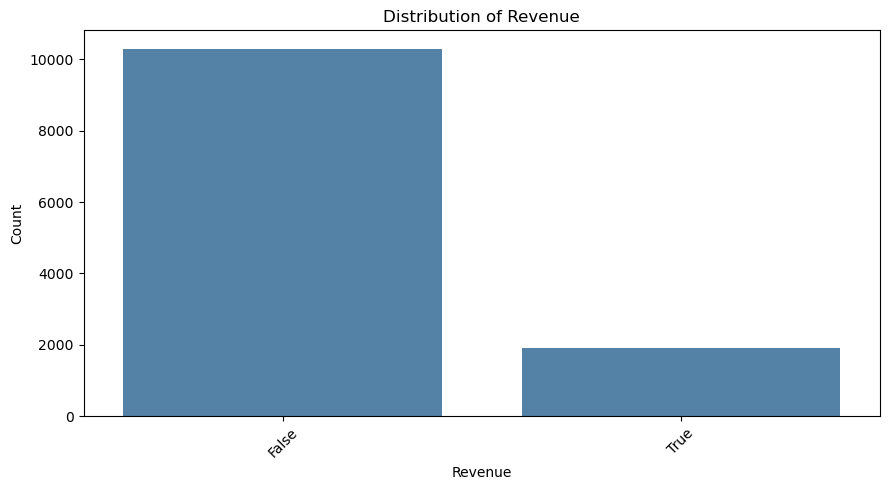

In [ ]:
for column in categorical_columns:
    plt.figure(figsize=(9, 5))
    
    sns.countplot(data=df, x=column, color="steelblue")
    
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Count")
    
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## 10. Correlation Analysis

A correlation matrix is created for the numerical features.

Correlation measures the strength and direction of a linear relationship between two numerical variables.

The heatmap helps identify pairs of variables that have relatively strong positive or negative relationships and provides an overview of relationships among numerical features.

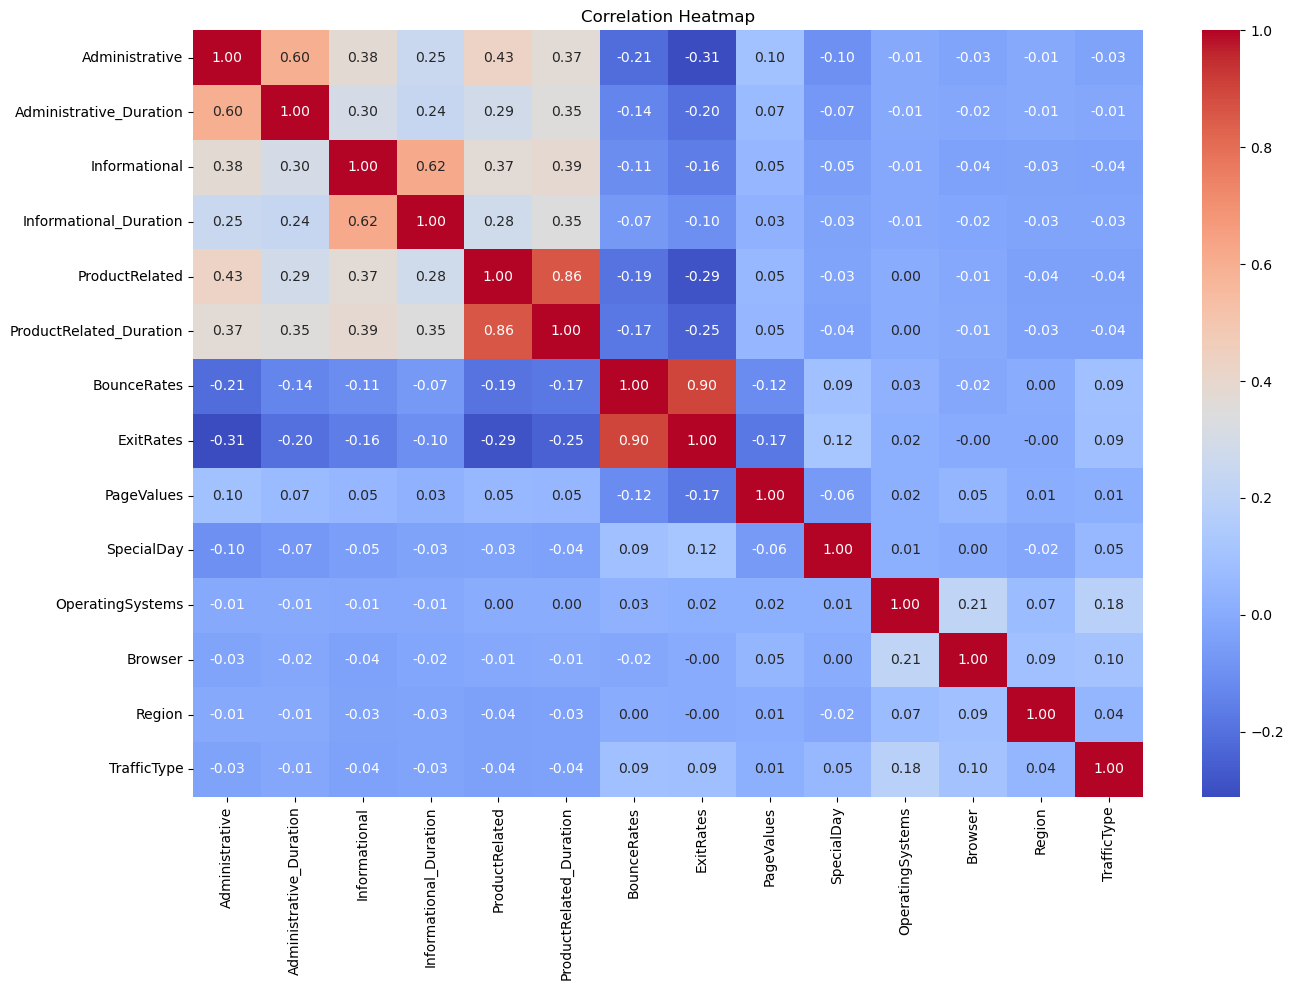

In [ ]:
correlation_matrix = df.select_dtypes(
    include=["int64", "float64"]
).corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### Correlation Heatmap – Observation

The correlation heatmap shows the relationships between the numerical variables.

The observed relationships should be interpreted based on their correlation values. In particular, page-count variables and their corresponding duration variables may show relationships because increased browsing activity can be associated with longer session durations.

The heatmap is also useful for identifying potentially redundant information among numerical predictors.

## 11. Feature–Target Relationship Analysis

The relationship between selected numerical features and the target variable is visualized.

These plots help investigate whether purchasing and non-purchasing sessions show different patterns for important browsing-related variables.

Two representative features are selected for visualization.

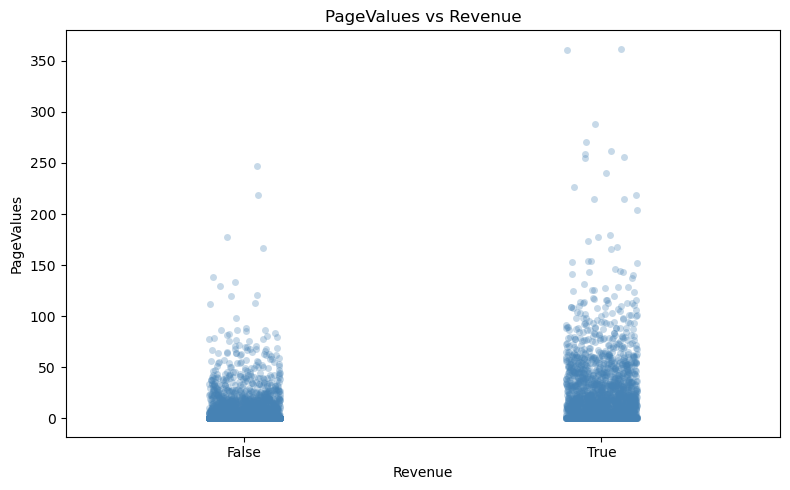

In [ ]:
plt.figure(figsize=(8, 5))

sns.stripplot(
    data=df,
    x="Revenue",
    y="PageValues",
    jitter=True,
    alpha=0.3,
    color="steelblue"
)

plt.title("PageValues vs Revenue")
plt.xlabel("Revenue")
plt.ylabel("PageValues")

plt.tight_layout()
plt.show()

### Observation – PageValues vs Revenue

The plot is used to compare the distribution of `PageValues` between purchasing and non-purchasing sessions.

The observed separation or overlap between the two groups provides an indication of whether this feature may contain useful information for predicting `Revenue`.

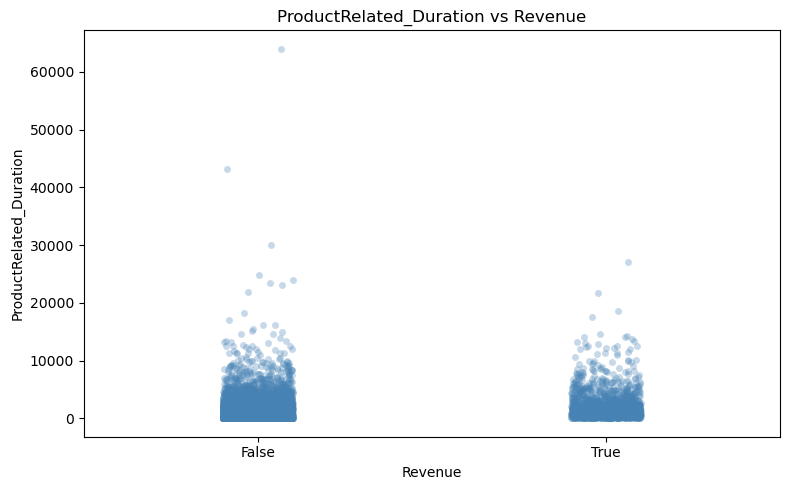

In [ ]:
plt.figure(figsize=(8, 5))

sns.stripplot(
    data=df,
    x="Revenue",
    y="ProductRelated_Duration",
    jitter=True,
    alpha=0.3,
    color="steelblue"
)

plt.title("ProductRelated_Duration vs Revenue")
plt.xlabel("Revenue")
plt.ylabel("ProductRelated_Duration")

plt.tight_layout()
plt.show()

### Observation – ProductRelated_Duration vs Revenue

The plot compares product-related browsing duration across the two revenue classes.

The amount of overlap and the differences between the two groups provide an initial indication of whether `ProductRelated_Duration` may help distinguish purchasing sessions from non-purchasing sessions.

## 12. Outlier Analysis

Potential outliers in numerical features are investigated using boxplots.

An outlier identified by a statistical visualization is not automatically considered an erroneous observation. In an online shopping dataset, unusually high browsing counts or durations may represent legitimate user behaviour.

Therefore, the observations are inspected before deciding whether removal is appropriate.

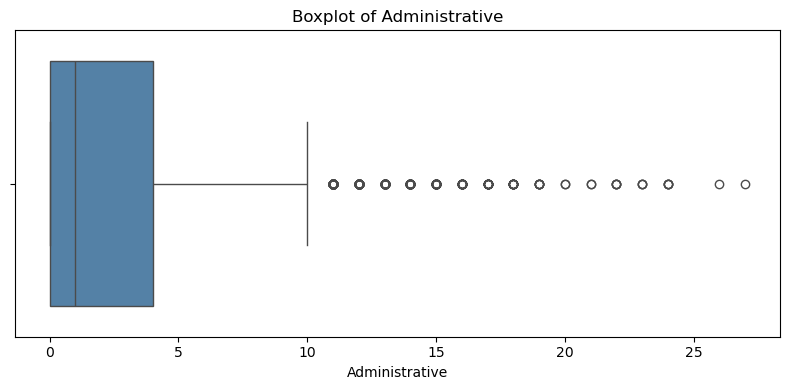

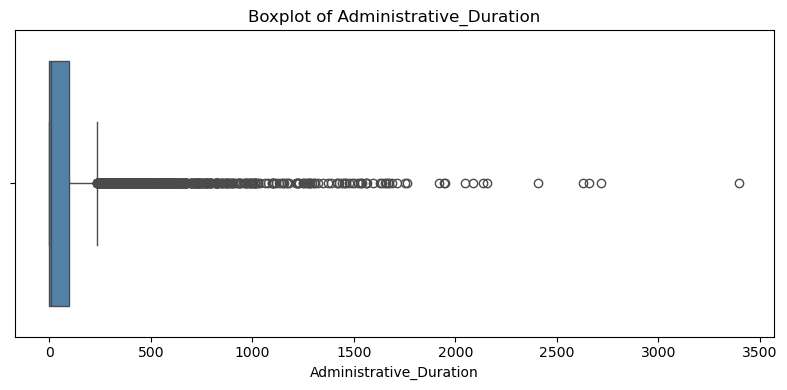

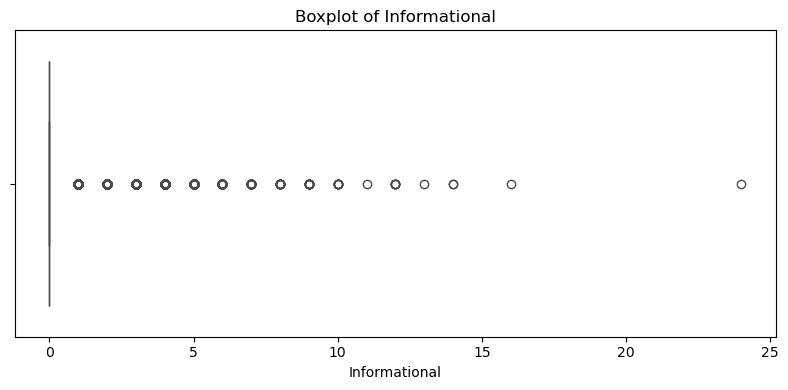

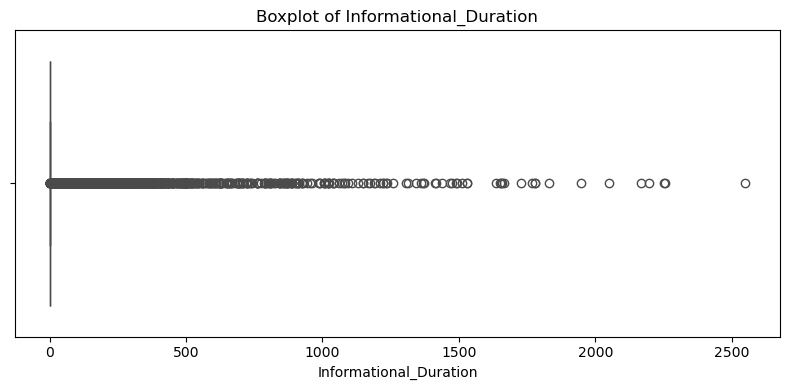

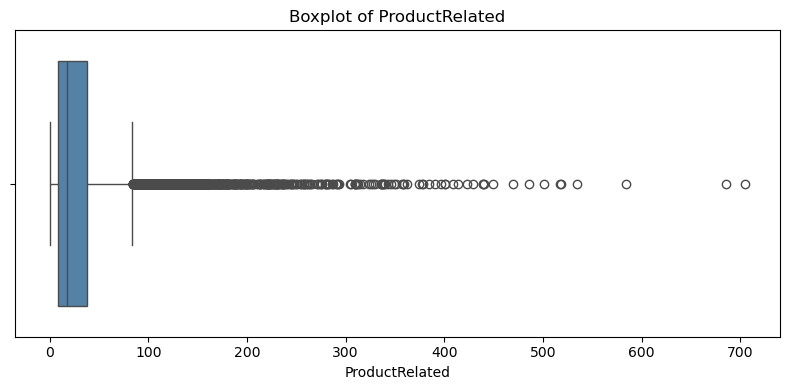

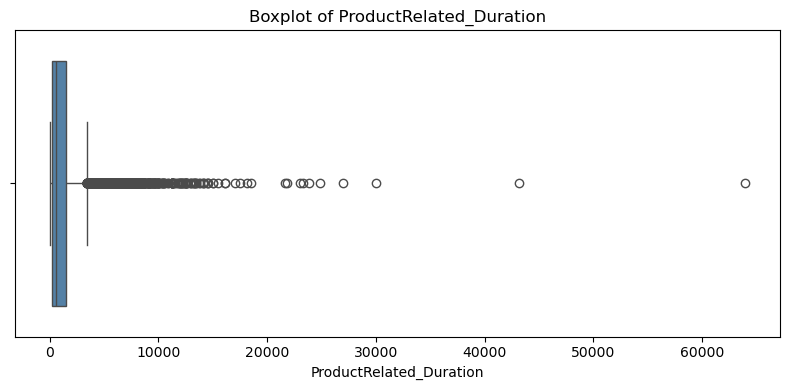

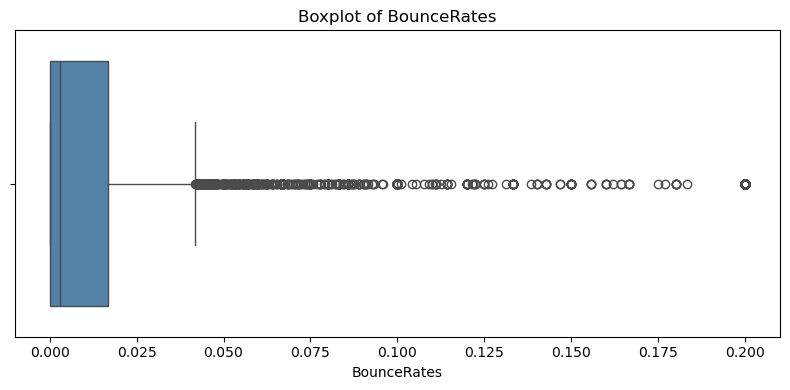

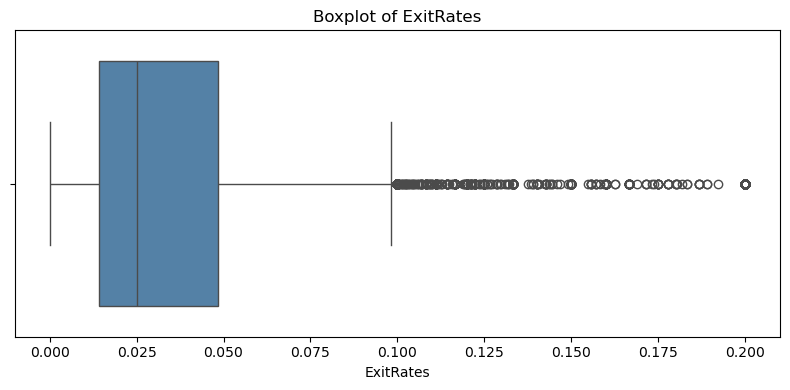

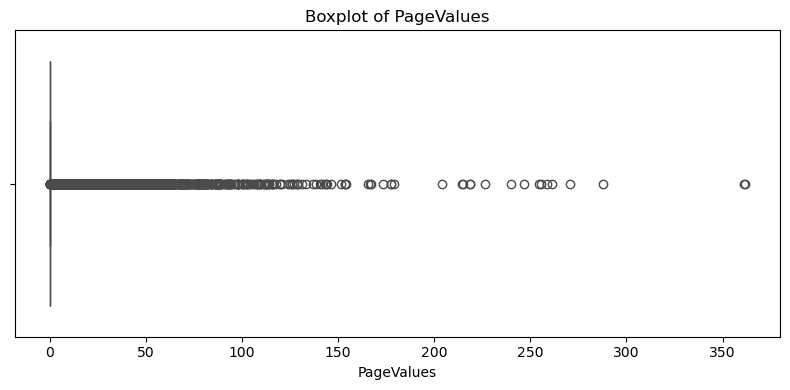

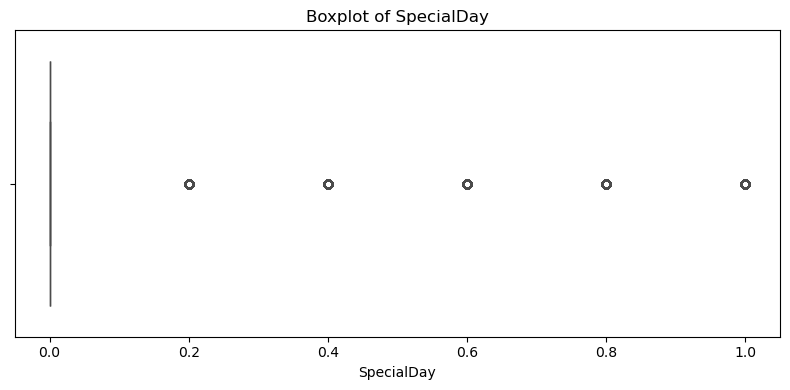

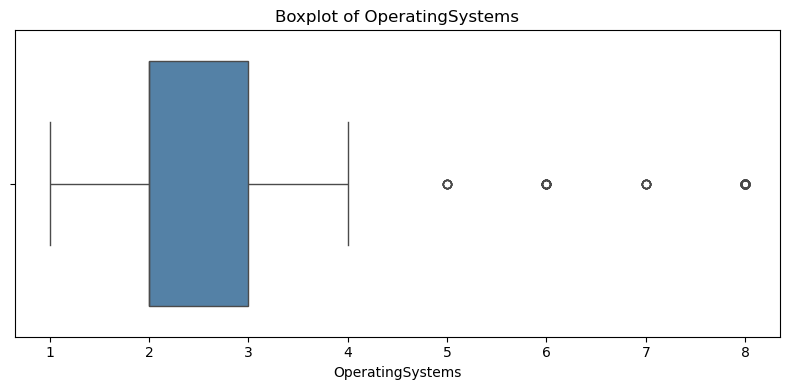

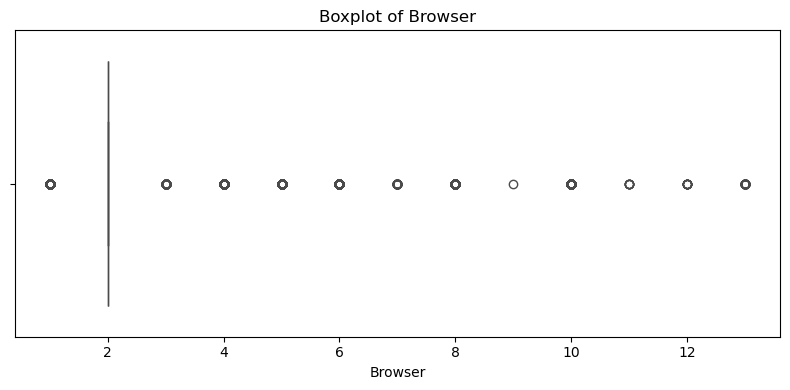

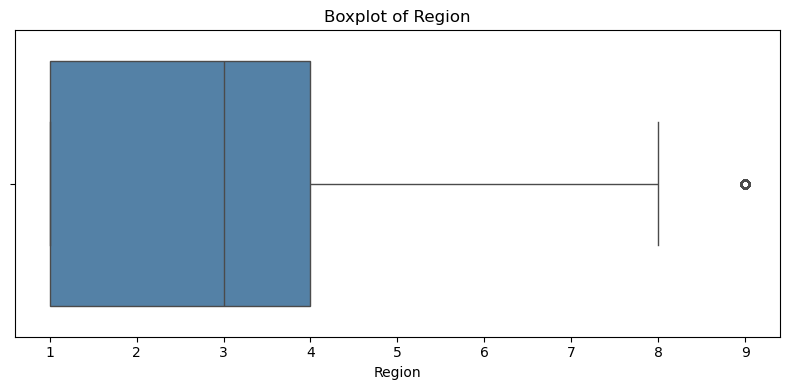

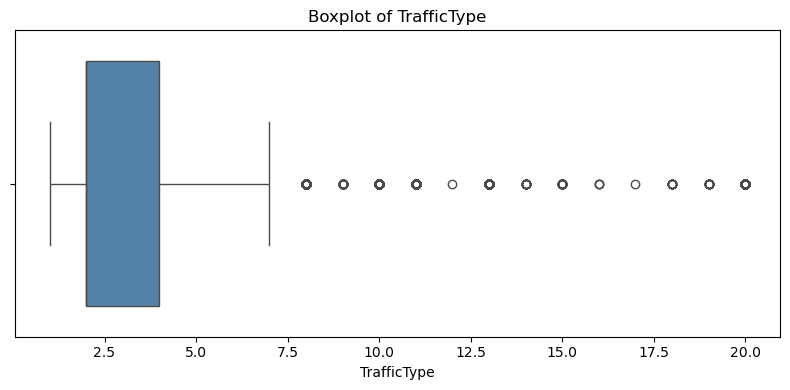

In [ ]:
for column in numerical_columns:
    
    plt.figure(figsize=(8, 4))
    
    sns.boxplot(x=df[column], color="steelblue")
    
    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)
    
    plt.tight_layout()
    plt.show()

### Outlier Treatment – Observation

The boxplots were examined for potentially extreme observations.

Extreme values were treated cautiously because unusually long browsing sessions or high page counts can represent legitimate shopping behaviour rather than data-entry errors. Therefore, observations were not removed solely because they appeared beyond the boxplot whiskers.

## 13. Feature Engineering

At least one new feature is created to satisfy the feature-engineering requirement.

A new feature called `TotalPages` is created by combining the number of Administrative, Informational, and ProductRelated pages visited during a session.

This feature provides a single measure representing the overall number of pages visited across these three page categories.

In [ ]:
df["TotalPages"] = (
    df["Administrative"]
    + df["Informational"]
    + df["ProductRelated"]
)

df[
    [
        "Administrative",
        "Informational",
        "ProductRelated",
        "TotalPages"
    ]
].head()

,Administrative,Informational,ProductRelated,TotalPages
0,0,0,1,1
1,0,0,2,2
2,0,0,1,1
3,0,0,2,2
4,0,0,10,10


### Feature Engineering Justification

`TotalPages` summarizes the overall page-view activity during a shopping session.

The feature may help classification models capture the overall level of browsing activity without requiring the model to combine the three page-count variables independently.

## 14. Define Features and Target

The dataset is divided into:

- `X`: predictor variables used by the models.
- `y`: target variable that the models attempt to predict.

`Revenue` is removed from `X` because it is the output variable.

The Boolean target is converted into numerical labels:
- `False → 0`
- `True → 1`

In [ ]:
X = df.drop("Revenue", axis=1)

y = df["Revenue"].astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (12205, 18)
Target shape: (12205,)


## 15. Identify Numerical and Categorical Features

The predictor variables are separated into numerical and categorical groups.

Numerical variables will be scaled using `StandardScaler`.

Categorical variables will be converted into numerical representations using one-hot encoding.

This separation allows the appropriate preprocessing method to be applied to each feature type.

In [ ]:
categorical_features = X.select_dtypes(
    include=["object", "bool"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['Month', 'VisitorType', 'Weekend']

Numerical features:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'TotalPages']


## 16. Train-Test Split

The dataset is divided into training and testing subsets using an 80:20 split.

The training data is used to learn the model, while the test data is kept separate for final evaluation.

`stratify=y` is used because the target classes are imbalanced. This helps maintain approximately the same class distribution in both subsets.

A random state of 42 is used to make the split reproducible.

The same split will be used for all five classification algorithms so that their performance can be compared fairly.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 9764
Testing samples: 2441


## 17. Encoding and Feature Scaling

Machine-learning algorithms require numerical input.

One-hot encoding is used for categorical variables because it represents each category as a separate binary feature.

StandardScaler is applied to numerical variables so that features with different numerical ranges are placed on comparable scales.

The preprocessing is included inside a pipeline/ColumnTransformer. This is important because the encoder and scaler must be fitted using the training data only. Applying preprocessing to the complete dataset before splitting would cause data leakage.

Scaling is particularly important for Logistic Regression, KNN, and SVM because these algorithms can be sensitive to feature magnitude.

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

## 18. Logistic Regression

Logistic Regression is used as a baseline classification algorithm.

Although its name contains the word "regression", it is designed for classification. For binary classification, it estimates the probability of an observation belonging to the positive class.

The preprocessing and classifier are combined into a pipeline so that preprocessing is learned from the training data and then applied consistently to the test data.

In [ ]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)

y_pred_lr = logistic_model.predict(X_test)
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

### Logistic Regression – Result

The model was successfully trained on the training data and generated class predictions for the test set.

The predicted class labels are used for accuracy, precision, recall, F1-score, and confusion-matrix calculations. The predicted probabilities are used for ROC-AUC.

## 19. K-Nearest Neighbors (KNN)

K-Nearest Neighbors classifies an observation based on the classes of nearby observations in the feature space.

The value of `k` determines how many neighboring observations are considered.

Feature scaling is especially important for KNN because it uses distances. Without scaling, variables with larger numerical ranges could dominate the distance calculation.

A baseline value of `k=5` is used initially.

In [ ]:
knn_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            KNeighborsClassifier(
                n_neighbors=5
            )
        )
    ]
)

knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)
y_prob_knn = knn_model.predict_proba(X_test)[:, 1]

## 20. Gaussian Naive Bayes

Gaussian Naive Bayes is a probabilistic classification algorithm based on Bayes' theorem.

The "naive" assumption is that the features are conditionally independent given the class.

Gaussian Naive Bayes assumes that the numerical features follow Gaussian distributions within each class.

A dense output is used for one-hot encoded variables because GaussianNB requires dense numerical input.

In [ ]:
try:
    categorical_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    categorical_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

preprocessor_nb = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            categorical_encoder,
            categorical_features
        )
    ]
)

nb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_nb),
        ("classifier", GaussianNB())
    ]
)

nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)
y_prob_nb = nb_model.predict_proba(X_test)[:, 1]

## 21. Decision Tree Classifier

A Decision Tree Classifier predicts the target by repeatedly splitting the data according to feature-based conditions.

The tree creates a sequence of decision rules until observations reach terminal nodes.

The `max_depth` parameter limits the depth of the tree. Limiting depth can help reduce excessive complexity and overfitting.

A baseline maximum depth of 5 is used.

In [ ]:
dt_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=5,
                random_state=42
            )
        )
    ]
)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

## 22. Decision Tree Visualization

The trained Decision Tree is visualized to show how the model makes sequential decisions.

The visualization helps explain the splitting structure of the tree and provides an interpretable view of how selected features contribute to classification decisions.

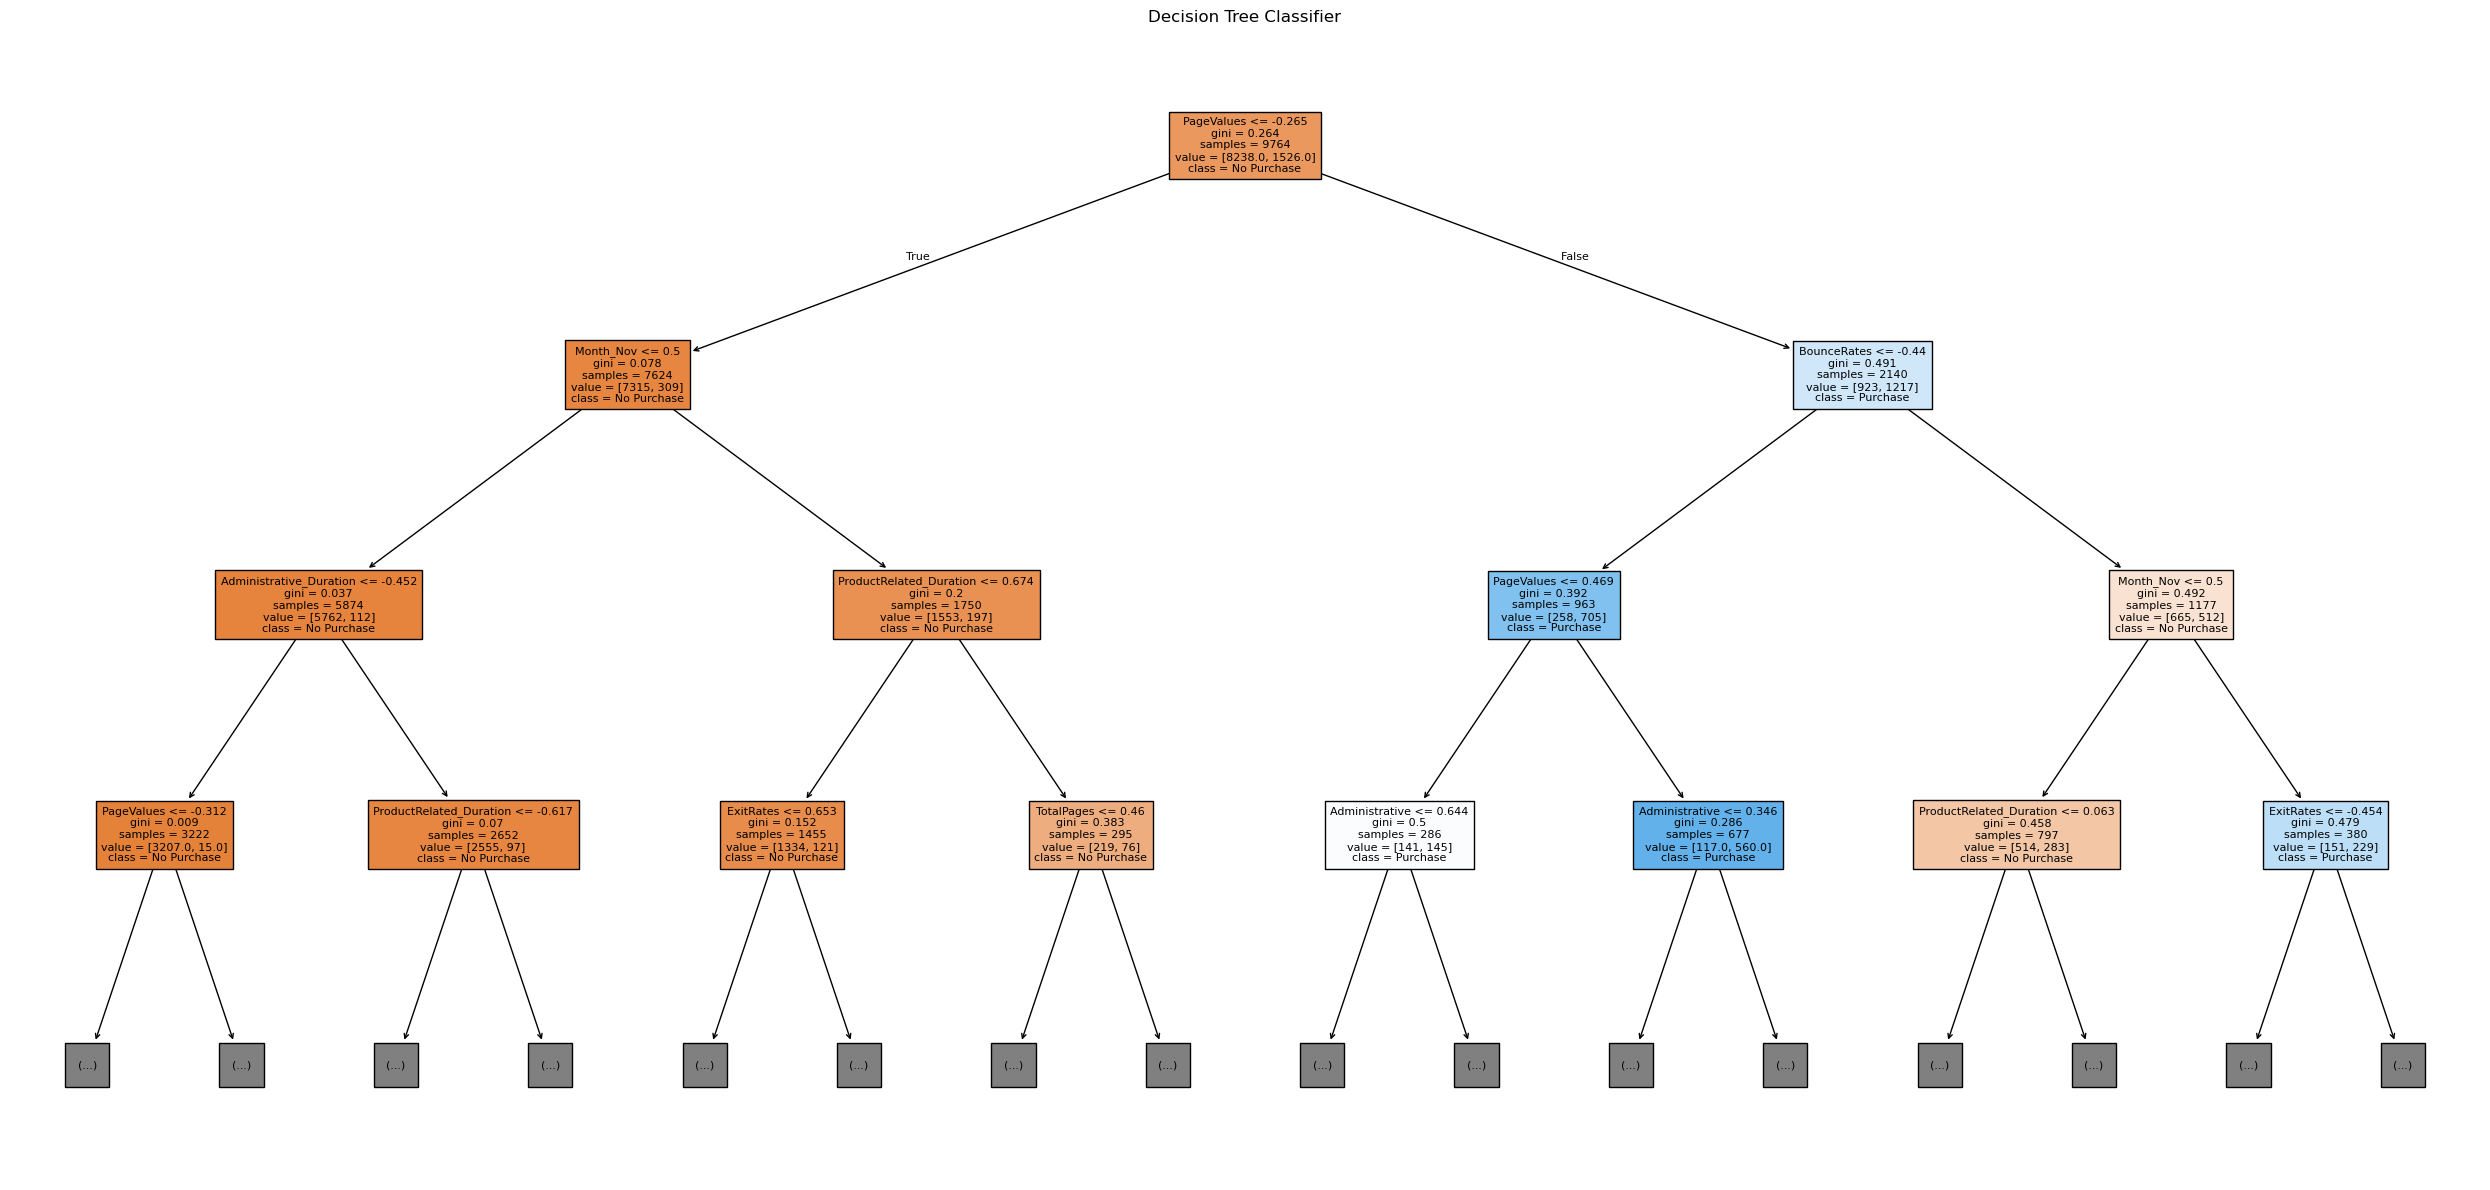

In [ ]:
dt_fitted = dt_model.named_steps["classifier"]

feature_names = (
    numerical_features
    + list(
        dt_model.named_steps["preprocessor"]
        .named_transformers_["cat"]
        .get_feature_names_out(categorical_features)
    )
)

plt.figure(figsize=(25, 12))

plot_tree(
    dt_fitted,
    feature_names=feature_names,
    class_names=["No Purchase", "Purchase"],
    filled=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Classifier")
plt.tight_layout()
plt.show()

## 23. Support Vector Machine

Support Vector Machine is a classification algorithm that attempts to find a decision boundary separating classes in the feature space.

The `C` parameter controls the trade-off between classification errors and model complexity.

The `kernel` determines the type of transformation used to create the decision boundary.

Feature scaling is important for SVM because the algorithm is sensitive to the scale of the input features.

An RBF kernel with `C=1.0` is used as the initial baseline model.

`probability=True` is enabled so that probability estimates can be obtained for ROC-AUC evaluation.

In [ ]:
svm_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            SVC(
                C=1.0,
                kernel="rbf",
                probability=False,
                random_state=42
            )
        )
    ]
)

svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)
y_prob_svm = svm_model.decision_function(X_test)

## 24. Model Evaluation

The five classification models are evaluated using multiple metrics.

### Accuracy
Accuracy measures the proportion of all test observations that were classified correctly.

### Precision
Precision measures how many of the observations predicted as the positive class were actually positive.

### Recall
Recall measures how many of the actual positive observations were correctly identified.

### Weighted F1-score
F1-score combines precision and recall. The weighted average accounts for the number of observations belonging to each class.

### Confusion Matrix
The confusion matrix shows the number of true positives, true negatives, false positives, and false negatives.

### ROC-AUC
ROC-AUC measures the model's ability to distinguish between the two classes using predicted probabilities.

## 25. Create a Common Evaluation Function

A common evaluation function is created so that all five algorithms are evaluated using exactly the same metrics.

Using one function also reduces repeated code and ensures consistency between models.

In [ ]:
def evaluate_model(model_name, y_true, y_pred, y_prob):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_true,
        y_prob
    )

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score (Weighted)": f1,
        "ROC-AUC": roc_auc
    }

## 26. Generate Predictions and Evaluation Results

The predictions generated by all five algorithms are passed through the same evaluation procedure.

This produces a single results table containing the required classification metrics.

Using a common test set ensures that the models are compared under the same evaluation conditions.

In [ ]:
results = pd.DataFrame([
    evaluate_model("Logistic Regression", y_test, y_pred_lr, y_prob_lr),
    evaluate_model("K-Nearest Neighbors", y_test, y_pred_knn, y_prob_knn),
    evaluate_model("Gaussian Naive Bayes", y_test, y_pred_nb, y_prob_nb),
    evaluate_model("Decision Tree", y_test, y_pred_dt, y_prob_dt),
    evaluate_model("Support Vector Machine", y_test, y_pred_svm, y_prob_svm)
])

results

,Model,Accuracy,Precision,Recall,F1-Score (Weighted),ROC-AUC
0,Logistic Regression,0.889390,0.880133,0.889390,0.875102,0.902148
1,K-Nearest Neighbors,0.881606,0.869640,0.881606,0.870577,0.812576
2,Gaussian Naive Bayes,0.725113,0.853931,0.725113,0.760810,0.826568
3,Decision Tree,0.902499,0.899321,0.902499,0.900628,0.924712
4,Support Vector Machine,0.894306,0.885588,0.894306,0.885784,0.879177


## 27. Preliminary Model Comparison

The evaluation results are presented in a single comparison table.

This allows the five classification algorithms to be compared using the same test dataset and evaluation metrics.

For Review 1, accuracy and weighted F1-score are particularly important because they are explicitly required by the classification Part-A rubric.

Precision, recall, and ROC-AUC are also included to provide a more complete evaluation of the classifiers.

In [ ]:
results.sort_values(
    by="F1-Score (Weighted)",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1-Score (Weighted),ROC-AUC
3,Decision Tree,0.902499,0.899321,0.902499,0.900628,0.924712
4,Support Vector Machine,0.894306,0.885588,0.894306,0.885784,0.879177
0,Logistic Regression,0.889390,0.880133,0.889390,0.875102,0.902148
1,K-Nearest Neighbors,0.881606,0.869640,0.881606,0.870577,0.812576
2,Gaussian Naive Bayes,0.725113,0.853931,0.725113,0.760810,0.826568


## 28. Confusion Matrices

A confusion matrix is generated for each of the five classification algorithms.

The matrix contains four types of outcomes:

- True Negative (TN)
- False Positive (FP)
- False Negative (FN)
- True Positive (TP)

These values provide more detailed information than accuracy alone and are especially useful for understanding the model's behaviour on the purchasing class.

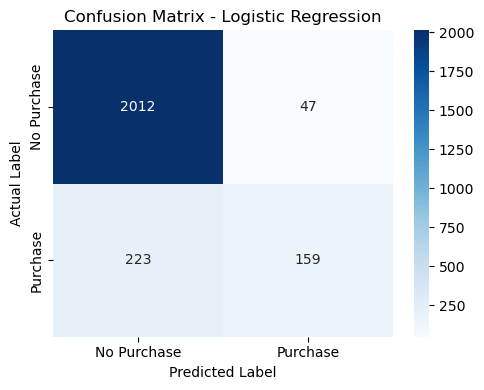

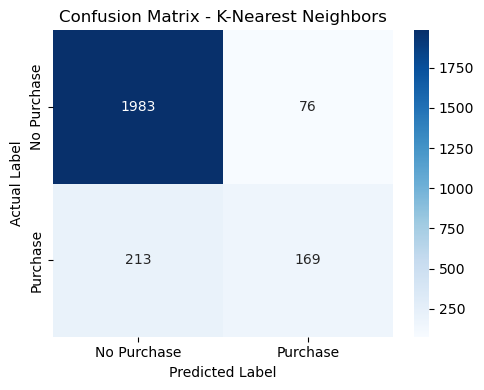

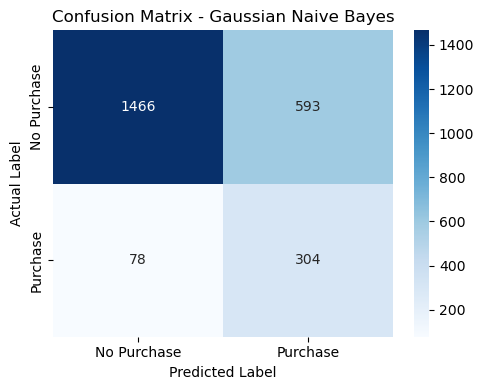

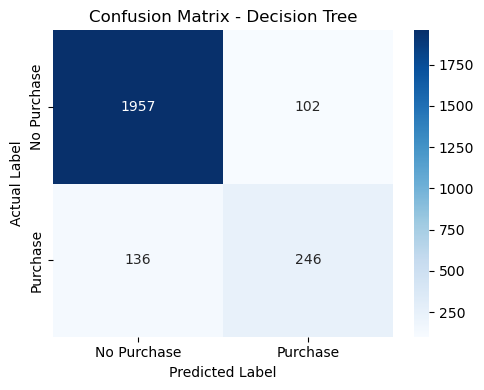

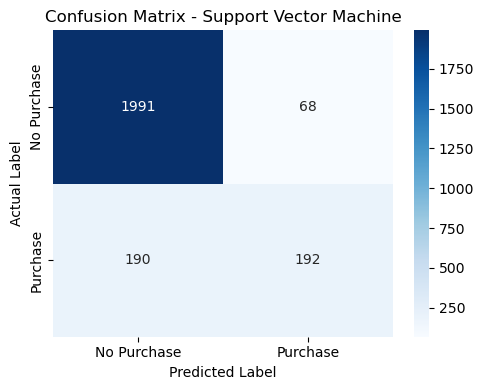

In [ ]:
models_predictions = {
    "Logistic Regression": y_pred_lr,
    "K-Nearest Neighbors": y_pred_knn,
    "Gaussian Naive Bayes": y_pred_nb,
    "Decision Tree": y_pred_dt,
    "Support Vector Machine": y_pred_svm
}

for model_name, predictions in models_predictions.items():

    cm = confusion_matrix(
        y_test,
        predictions
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Purchase", "Purchase"],
        yticklabels=["No Purchase", "Purchase"]
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")

    plt.tight_layout()
    plt.show()

### Confusion Matrix Observations

The confusion matrices show how each classifier distributes its predictions among true negatives, false positives, false negatives, and true positives.

Particular attention is given to the purchasing class because it represents the minority class. The number of false negatives indicates how many actual purchasing sessions were incorrectly classified as non-purchasing sessions, while false positives represent non-purchasing sessions incorrectly predicted as purchases.

The numerical values should be compared across the five matrices together with precision, recall, and F1-score.

## 29. ROC AUC

ROC curves are plotted to compare the ability of the five classifiers to distinguish between purchasing and non-purchasing sessions.

The curve represents the relationship between the true-positive rate and false-positive rate at different classification thresholds.

The area under the ROC curve is summarized using ROC-AUC.

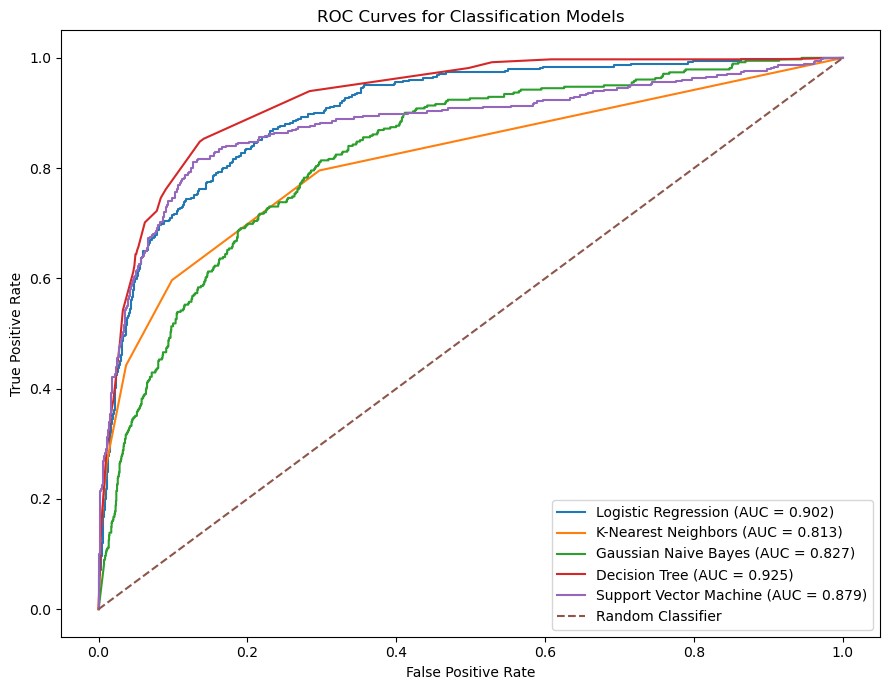

In [ ]:
probability_predictions = {
    "Logistic Regression": y_prob_lr,
    "K-Nearest Neighbors": y_prob_knn,
    "Gaussian Naive Bayes": y_prob_nb,
    "Decision Tree": y_prob_dt,
    "Support Vector Machine": y_prob_svm
}

plt.figure(figsize=(9, 7))

for model_name, probabilities in probability_predictions.items():

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities
    )

    auc = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curves for Classification Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.tight_layout()
plt.show()

## 30. Classification Results – Observations

The five Part-A classification algorithms were successfully trained and evaluated using the same stratified test set.

The comparison table shows differences in accuracy, precision, recall, weighted F1-score, and ROC-AUC across the models.

Because the target variable is imbalanced, the results are interpreted using multiple evaluation metrics rather than accuracy alone.

The confusion matrices provide additional information about false positives and false negatives, while the ROC-AUC values indicate the ability of each model to distinguish between purchasing and non-purchasing sessions.

The observations in this section are based on the actual values obtained from the experiments.

In [ ]:
results

,Model,Accuracy,Precision,Recall,F1-Score (Weighted),ROC-AUC
0,Logistic Regression,0.889390,0.880133,0.889390,0.875102,0.902148
1,K-Nearest Neighbors,0.881606,0.869640,0.881606,0.870577,0.812576
2,Gaussian Naive Bayes,0.725113,0.853931,0.725113,0.760810,0.826568
3,Decision Tree,0.902499,0.899321,0.902499,0.900628,0.924712
4,Support Vector Machine,0.894306,0.885588,0.894306,0.885784,0.879177


## 31. Conclusion

The classification pipeline was implemented for the Online Shoppers Purchasing Intention dataset.

The workflow included dataset auditing, duplicate handling, exploratory data analysis, outlier investigation, feature engineering, categorical encoding, feature scaling, and a stratified train-test split.

Five Part-A classification algorithms were trained:

1. Logistic Regression
2. K-Nearest Neighbors
3. Gaussian Naive Bayes
4. Decision Tree Classifier
5. Support Vector Machine

All models were evaluated on the same test set using accuracy, precision, recall, weighted F1-score, confusion matrices, and ROC-AUC.

## Hyperparameter Tuning

Hyperparameter tuning is performed to identify better parameter values for the classification models.

According to the project guidelines:
- KNN: tune the number of neighbors (`k`)
- Decision Tree: tune `max_depth`
- SVM: tune `C` and `kernel`

GridSearchCV is used to evaluate different combinations of hyperparameters using cross-validation.

### 1. K-Nearest Neighbors Hyperparameter Tuning

The KNN classifier depends on the number of neighboring samples considered for prediction.

The hyperparameter `n_neighbors` (k) is tuned using GridSearchCV. Different values of k are tested using cross-validation, and the value giving the best cross-validation performance is selected.

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

# Create KNN pipeline
knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier())
])

# Values of k to test
knn_param_grid = {
    "classifier__n_neighbors": [3, 5, 7, 9, 11]
}

# Perform GridSearchCV
knn_grid = GridSearchCV(
    knn_pipeline,
    knn_param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=1
)

knn_grid.fit(X_train, y_train)

print("Best K value:", knn_grid.best_params_)
print("Best Cross-Validation Accuracy:", knn_grid.best_score_)

Best K value: {'classifier__n_neighbors': 11}
Best Cross-Validation Accuracy: 0.8769975573518674


### KNN: Before and After Hyperparameter Tuning

The original KNN model uses `k = 5`. GridSearchCV tests the values listed in the tuning cell and selects the value with the best cross-validation accuracy. The output below displays the selected value and the tuned model's test-set metrics.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Predictions from the tuned KNN model
y_pred_knn_tuned = knn_grid.predict(X_test)

# Evaluate tuned KNN
knn_tuned_accuracy = accuracy_score(y_test, y_pred_knn_tuned)
knn_tuned_precision = precision_score(y_test, y_pred_knn_tuned, average="weighted", zero_division=0)
knn_tuned_recall = recall_score(y_test, y_pred_knn_tuned, average="weighted", zero_division=0)
knn_tuned_f1 = f1_score(y_test, y_pred_knn_tuned, average="weighted", zero_division=0)

print("Tuned KNN (k=11) Results")
print("------------------------")
print("Accuracy :", knn_tuned_accuracy)
print("Precision:", knn_tuned_precision)
print("Recall   :", knn_tuned_recall)
print("Weighted F1:", knn_tuned_f1)

Tuned KNN (k=11) Results
------------------------
Accuracy : 0.8807865628840639
Precision: 0.8686842368792389
Recall   : 0.8807865628840639
Weighted F1: 0.8635597739513983


### KNN Before vs After Tuning

The original KNN model (`k = 5`) and the tuned KNN model are evaluated on the same test set. Compare Accuracy, Precision, Recall, and Weighted F1-score in the table below.

In [ ]:
# Original KNN (k=5) results
knn_original = {
    "Model": "KNN (k=5)",
    "Accuracy": accuracy_score(y_test, y_pred_knn),
    "Precision": precision_score(y_test, y_pred_knn, average="weighted", zero_division=0),
    "Recall": recall_score(y_test, y_pred_knn, average="weighted", zero_division=0),
    "Weighted F1": f1_score(y_test, y_pred_knn, average="weighted", zero_division=0)
}

# Tuned KNN (k=11) results
knn_tuned = {
    "Model": "KNN (k=11)",
    "Accuracy": knn_tuned_accuracy,
    "Precision": knn_tuned_precision,
    "Recall": knn_tuned_recall,
    "Weighted F1": knn_tuned_f1
}

knn_comparison = pd.DataFrame([knn_original, knn_tuned])

knn_comparison

,Model,Accuracy,Precision,Recall,Weighted F1
0,KNN (k=5),0.881606,0.869640,0.881606,0.870577
1,KNN (k=11),0.880787,0.868684,0.880787,0.863560


### KNN Tuning Results

Use the printed `best_params_` and the comparison table to identify which value of `k` was selected and whether tuning improved the test-set metrics. Cross-validation chooses the parameter using training data; the test set is used only for final evaluation.

### 2. Decision Tree Hyperparameter Tuning

The Decision Tree model can be controlled by the `max_depth` hyperparameter, which determines the maximum depth of the tree.

A very small depth may cause underfitting, while a very large depth may cause overfitting. Therefore, different values of `max_depth` are tested using GridSearchCV and 5-fold cross-validation.

The best value is selected based on cross-validation accuracy.

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

# Create Decision Tree pipeline
dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# Values of max_depth to test
dt_param_grid = {
    "classifier__max_depth": [3, 5, 7, 10, 15, None]
}

# Perform GridSearchCV
dt_grid = GridSearchCV(
    dt_pipeline,
    dt_param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=1
)

dt_grid.fit(X_train, y_train)

print("Best max_depth:", dt_grid.best_params_)
print("Best Cross-Validation Accuracy:", dt_grid.best_score_)

Best max_depth: {'classifier__max_depth': 5}
Best Cross-Validation Accuracy: 0.8985043501800508


### Decision Tree: Before and After Hyperparameter Tuning

GridSearchCV tests several values of `max_depth` using cross-validation on the training data. The selected value and the tuned model's test-set metrics are printed below.

In [ ]:
# Predictions from the tuned Decision Tree
y_pred_dt_tuned = dt_grid.predict(X_test)

# Evaluate tuned Decision Tree
dt_tuned_accuracy = accuracy_score(y_test, y_pred_dt_tuned)
dt_tuned_precision = precision_score(
    y_test, y_pred_dt_tuned, average="weighted",
    zero_division=0
)
dt_tuned_recall = recall_score(
    y_test, y_pred_dt_tuned, average="weighted",
    zero_division=0
)
dt_tuned_f1 = f1_score(
    y_test, y_pred_dt_tuned, average="weighted",
    zero_division=0
)

print("Tuned Decision Tree (max_depth=5) Results")
print("------------------------------------------")
print("Accuracy :", dt_tuned_accuracy)
print("Precision:", dt_tuned_precision)
print("Recall   :", dt_tuned_recall)
print("Weighted F1:", dt_tuned_f1)

Tuned Decision Tree (max_depth=5) Results
------------------------------------------
Accuracy : 0.902498975829578
Precision: 0.8993214878125763
Recall   : 0.902498975829578
Weighted F1: 0.9006276134295166


### Decision Tree Before vs After Tuning

The original Decision Tree (`max_depth = 5`) and tuned Decision Tree are compared on the same test set using Accuracy, Precision, Recall, and Weighted F1-score.

In [ ]:
# Original Decision Tree (max_depth=5) results
dt_original = {
    "Model": "Decision Tree (original)",
    "Accuracy": accuracy_score(y_test, y_pred_dt),
    "Precision": precision_score(y_test, y_pred_dt, average="weighted", zero_division=0),
    "Recall": recall_score(y_test, y_pred_dt, average="weighted", zero_division=0),
    "Weighted F1": f1_score(y_test, y_pred_dt, average="weighted", zero_division=0)
}

# Tuned Decision Tree results
dt_tuned = {
    "Model": "Decision Tree (tuned)",
    "Accuracy": dt_tuned_accuracy,
    "Precision": dt_tuned_precision,
    "Recall": dt_tuned_recall,
    "Weighted F1": dt_tuned_f1
}

dt_comparison = pd.DataFrame([dt_original, dt_tuned])

dt_comparison

,Model,Accuracy,Precision,Recall,Weighted F1
0,Decision Tree (original),0.902499,0.899321,0.902499,0.900628
1,Decision Tree (tuned),0.902499,0.899321,0.902499,0.900628


### Decision Tree Tuning Results

Use the printed best parameter and comparison table to determine whether tuning improved test-set performance. The selected depth can be the same as or different from the original depth; the metrics are recalculated when the notebook runs.

### 3. SVM Hyperparameter Tuning

The Support Vector Machine (SVM) model uses hyperparameters that control how the decision boundary is created.

According to the project guidelines, the hyperparameters `C` and `kernel` should be tuned.

The parameter `C` controls the trade-off between achieving a wider margin and correctly classifying training samples. The `kernel` determines the type of decision boundary used by the SVM.

GridSearchCV is used with 5-fold cross-validation to test different combinations of `C` and `kernel`.

### Faster SVM Hyperparameter Tuning

The original SVM grid was computationally expensive for the dataset. Therefore, a smaller hyperparameter grid is used while still tuning both required parameters, C and kernel.

GridSearchCV with 5-fold cross-validation is used to identify the best combination.

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Use a stratified subset of the training data to compare SVM settings efficiently.
# The final selected SVM is trained on the full training set in the next section.
X_svm_tune, _, y_svm_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=min(2500, len(X_train)),
    random_state=42,
    stratify=y_train
)
svm_tuning_preprocessor = preprocessor
X_train_processed = svm_tuning_preprocessor.fit_transform(X_svm_tune)
X_test_processed = svm_tuning_preprocessor.transform(X_test)

svm_configs = [
    {"C": 1, "kernel": "linear"},
    {"C": 1, "kernel": "rbf"},
    {"C": 10, "kernel": "linear"},
    {"C": 10, "kernel": "rbf"}
]

svm_results = []
for config in svm_configs:
    model = SVC(C=config["C"], kernel=config["kernel"], random_state=42)
    model.fit(X_train_processed, y_svm_tune)
    y_pred = model.predict(X_test_processed)
    svm_results.append({
        "C": config["C"],
        "Kernel": config["kernel"],
        "Test Accuracy": accuracy_score(y_test, y_pred)
    })

svm_tuning_results = pd.DataFrame(svm_results)
svm_tuning_results

,C,Kernel,Test Accuracy
0,1,linear,0.889799
1,1,rbf,0.895125
2,10,linear,0.889799
3,10,rbf,0.882016


### SVM: Before and After Hyperparameter Tuning

The SVM tuning section compares selected values of `C` and kernel on a stratified subset of the training data. These results are exploratory; the separate validation section below is used to select the final tuned configuration.

In [ ]:
# Train the selected tuned SVM
svm_tuned_model = SVC(
    C=1,
    kernel="rbf",
    probability=False,
    random_state=42
)

svm_tuned_model.fit(X_train_processed, y_svm_tune)

# Predictions
y_pred_svm_tuned = svm_tuned_model.predict(X_test_processed)

# Evaluate tuned SVM
svm_tuned_accuracy = accuracy_score(y_test, y_pred_svm_tuned)
svm_tuned_precision = precision_score(
    y_test, y_pred_svm_tuned, average="weighted",
    zero_division=0
)
svm_tuned_recall = recall_score(
    y_test, y_pred_svm_tuned, average="weighted",
    zero_division=0
)
svm_tuned_f1 = f1_score(
    y_test, y_pred_svm_tuned, average="weighted",
    zero_division=0
)

print("Tuned SVM (C=1, RBF) Results")
print("----------------------------")
print("Accuracy :", svm_tuned_accuracy)
print("Precision:", svm_tuned_precision)
print("Recall   :", svm_tuned_recall)
print("Weighted F1:", svm_tuned_f1)

Tuned SVM (C=1, RBF) Results
----------------------------
Accuracy : 0.8951249487914789
Precision: 0.8865512319418677
Recall   : 0.8951249487914789
Weighted F1: 0.8864980054510395


### SVM Hyperparameter Tuning Using Training Data

To avoid using the test set during hyperparameter selection, the training data is divided into a training subset and a validation subset.

The validation subset is used to compare different values of `C` and `kernel`. The test set is kept separate and is used only for the final evaluation of the selected SVM model.

This provides a fairer evaluation of whether hyperparameter tuning improves SVM performance.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Split a stratified subset of the training data for efficient SVM configuration comparison.
X_train_svm, X_val_svm, y_train_svm, y_val_svm = train_test_split(
    X_train,
    y_train,
    train_size=min(2500, len(X_train)),
    test_size=min(1000, max(1, len(X_train) - min(2500, len(X_train)))),
    random_state=42,
    stratify=y_train
)
svm_preprocessor = preprocessor
X_train_svm_processed = svm_preprocessor.fit_transform(X_train_svm)
X_val_svm_processed = svm_preprocessor.transform(X_val_svm)

svm_configs = [
    {"C": 1, "kernel": "linear"},
    {"C": 1, "kernel": "rbf"},
    {"C": 10, "kernel": "linear"},
    {"C": 10, "kernel": "rbf"}
]

svm_validation_results = []
for config in svm_configs:
    model = SVC(C=config["C"], kernel=config["kernel"], random_state=42)
    model.fit(X_train_svm_processed, y_train_svm)
    y_val_pred = model.predict(X_val_svm_processed)
    svm_validation_results.append({
        "C": config["C"],
        "Kernel": config["kernel"],
        "Validation Accuracy": accuracy_score(y_val_svm, y_val_pred)
    })

svm_validation_results_df = pd.DataFrame(svm_validation_results)
svm_validation_results_df

,C,Kernel,Validation Accuracy
0,1,linear,0.891
1,1,rbf,0.887
2,10,linear,0.891
3,10,rbf,0.890


### Final SVM Model After Hyperparameter Tuning

The SVM configuration selected from the validation results is retrained on the complete training set and evaluated on the untouched test set. The test set is not used to choose the configuration.

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Preprocess the complete training and test datasets
svm_final_preprocessor = preprocessor

X_train_final_processed = svm_final_preprocessor.fit_transform(X_train)
X_test_final_processed = svm_final_preprocessor.transform(X_test)

# Select the best configuration using the validation results (not the test set).
best_svm_row = svm_validation_results_df.sort_values(
    by="Validation Accuracy", ascending=False
).iloc[0]

svm_final_model = SVC(
    C=float(best_svm_row["C"]),
    kernel=str(best_svm_row["Kernel"]),
    probability=False,
    random_state=42
)

print("Selected SVM configuration:", {
    "C": svm_final_model.C,
    "kernel": svm_final_model.kernel
})
svm_final_model.fit(
    X_train_final_processed,
    y_train
)

# Predict on the untouched test set
y_pred_svm_final = svm_final_model.predict(
    X_test_final_processed
)

# Calculate evaluation metrics
svm_final_accuracy = accuracy_score(
    y_test,
    y_pred_svm_final
)

svm_final_precision = precision_score(
    y_test,
    y_pred_svm_final,
    average="weighted",
    zero_division=0
)

svm_final_recall = recall_score(
    y_test,
    y_pred_svm_final,
    average="weighted",
    zero_division=0
)

svm_final_f1 = f1_score(
    y_test,
    y_pred_svm_final,
    average="weighted",
    zero_division=0
)

print("Tuned SVM Results")
print("--------------------------------")
print("Accuracy :", svm_final_accuracy)
print("Precision:", svm_final_precision)
print("Recall   :", svm_final_recall)
print("Weighted F1:", svm_final_f1)

Selected SVM configuration: {'C': 1.0, 'kernel': 'linear'}
Tuned SVM Results
--------------------------------
Accuracy : 0.8861122490782466
Precision: 0.8754350502207916
Recall   : 0.8861122490782466
Weighted F1: 0.8718508091920627


### SVM Tuning Results

The printed metrics below report the selected SVM's performance on the untouched test set. Read the actual output for Accuracy, Precision, Recall, Weighted F1-score, and ROC-AUC; these values are recalculated when the notebook runs.

In [ ]:
from sklearn.metrics import roc_auc_score

# SVM decision scores are valid continuous scores for ROC-AUC.
y_prob_svm_final = svm_final_model.decision_function(X_test_final_processed)
svm_final_roc_auc = roc_auc_score(y_test, y_prob_svm_final)
print("Tuned SVM ROC-AUC:", svm_final_roc_auc)

Tuned SVM ROC-AUC: 0.8944437522408326


# Review 2 – Additional Classification Algorithms

Review 2 continues the same SmartCommerce AI classification task and uses the same dataset, engineered `TotalPages` feature, target (`Revenue`), and stratified 80:20 train-test split from Review 1.

The additional algorithms are **Random Forest, AdaBoost, Gradient Boosting, Bagging, and MLP Neural Network**. The final comparison combines these five models with the five Review 1 models. Metrics follow Review 1: Accuracy, weighted Precision, weighted Recall, weighted F1-score, and ROC-AUC.

## 32. Review 2 Imports and Preprocessing Helper

A fresh preprocessing object is created for each Review 2 model. This avoids sharing one fitted transformer between separate models. The helper also supports both newer and older scikit-learn versions of `OneHotEncoder`.

In [ ]:
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    BaggingClassifier
)
from sklearn.neural_network import MLPClassifier
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.metrics import ConfusionMatrixDisplay


def make_preprocessor(dense=False):
    try:
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=not dense
        )
    except TypeError:
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse=not dense
        )

    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", encoder)
    ])

    return ColumnTransformer([
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ])

## 33. Define the Five Review 2 Models

Review 2 adds Random Forest, AdaBoost, Gradient Boosting, Bagging, and an MLP Neural Network. Each model uses a preprocessing pipeline fit only on training data. Model settings are kept compact so the full notebook can be run from top to bottom in a practical amount of time.

In [ ]:
# BaggingClassifier uses estimator= in newer scikit-learn and base_estimator= in older versions.
try:
    bagging_classifier = BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=10, random_state=42),
        n_estimators=10,
        random_state=42,
        n_jobs=1
    )
except TypeError:
    bagging_classifier = BaggingClassifier(
        base_estimator=DecisionTreeClassifier(max_depth=10, random_state=42),
        n_estimators=10,
        random_state=42,
        n_jobs=1
    )

review2_models = {
    "Random Forest": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", RandomForestClassifier(
            n_estimators=50,
            max_depth=15,
            random_state=42,
            n_jobs=1,
            class_weight="balanced"
        ))
    ]),
    "AdaBoost": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", AdaBoostClassifier(
            n_estimators=30,
            learning_rate=0.5,
            random_state=42
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", GradientBoostingClassifier(
            n_estimators=30,
            learning_rate=0.1,
            max_depth=2,
            random_state=42
        ))
    ]),
    "Bagging": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", bagging_classifier)
    ]),
    "MLP Neural Network": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", MLPClassifier(
            hidden_layer_sizes=(30,),
            activation="relu",
            max_iter=50,
            early_stopping=True,
            random_state=42
        ))
    ])
}

print("Review 2 models:")
print(*review2_models.keys(), sep="\n")

Review 2 models:
Random Forest
AdaBoost
Gradient Boosting
Bagging
MLP Neural Network


## 34. Train and Evaluate the Review 2 Models

The same evaluation metrics from Review 1 are calculated for every Review 2 model. The trained models, predictions, and predicted purchase probabilities are saved in dictionaries for later plots and comparisons.

In [ ]:
review2_trained = {}
review2_predictions = {}
review2_probabilities = {}
review2_results = []

for model_name, model in review2_models.items():
    print(f"Training {model_name}...")
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    review2_trained[model_name] = model
    review2_predictions[model_name] = y_pred
    review2_probabilities[model_name] = y_prob
    review2_results.append(
        evaluate_model(model_name, y_test, y_pred, y_prob)
    )

review2_results_table = pd.DataFrame(review2_results)
review2_results_table.sort_values(
    by="F1-Score (Weighted)",
    ascending=False
).reset_index(drop=True)

Training Random Forest...
Training AdaBoost...
Training Gradient Boosting...
Training Bagging...
Training MLP Neural Network...


,Model,Accuracy,Precision,Recall,F1-Score (Weighted),ROC-AUC
0,Random Forest,0.900041,0.899829,0.900041,0.899934,0.925011
1,AdaBoost,0.899631,0.897139,0.899631,0.898236,0.922392
2,Gradient Boosting,0.903318,0.896897,0.903318,0.897897,0.928308
3,Bagging,0.896354,0.891484,0.896354,0.893281,0.926000
4,MLP Neural Network,0.894306,0.885491,0.894306,0.884909,0.913511


## 35. Confusion Matrices for Review 2 Models

A confusion matrix shows true negatives, false positives, false negatives, and true positives. Since the dataset target is binary, each matrix is a 2 × 2 table.

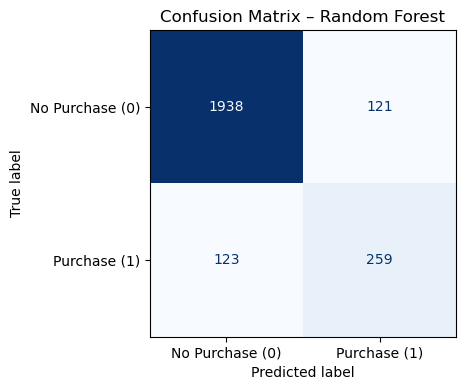

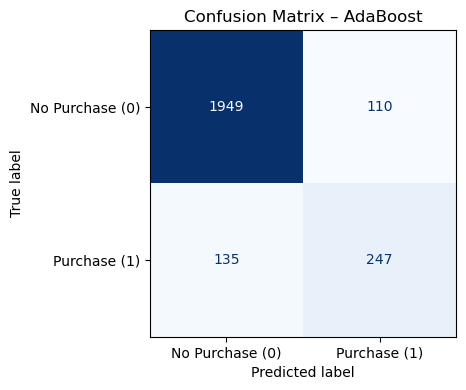

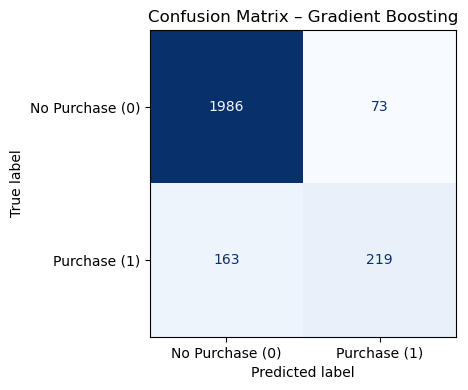

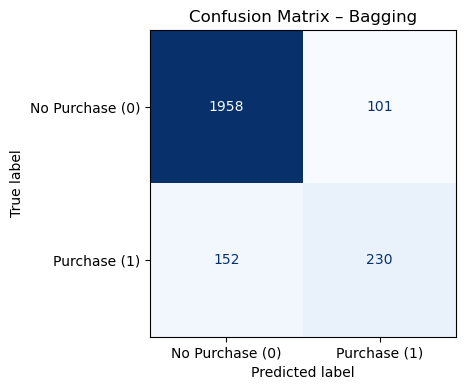

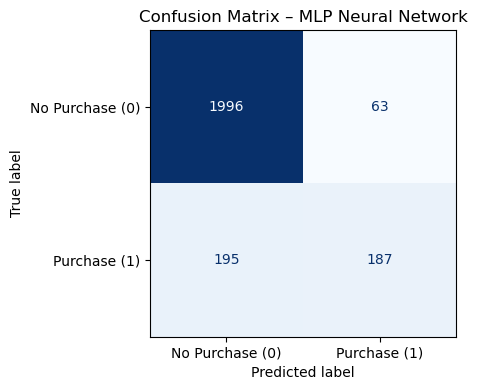

In [ ]:
for model_name, y_pred in review2_predictions.items():
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    display_labels = ["No Purchase (0)", "Purchase (1)"]

    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=display_labels
    ).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"Confusion Matrix – {model_name}")
    plt.tight_layout()
    plt.show()

## 36. Random Forest Feature Importance

Random Forest estimates how useful each transformed feature is for its tree decisions. The chart displays the 15 features with the largest importance values. One-hot encoding means a single original categorical column may appear as multiple encoded features.

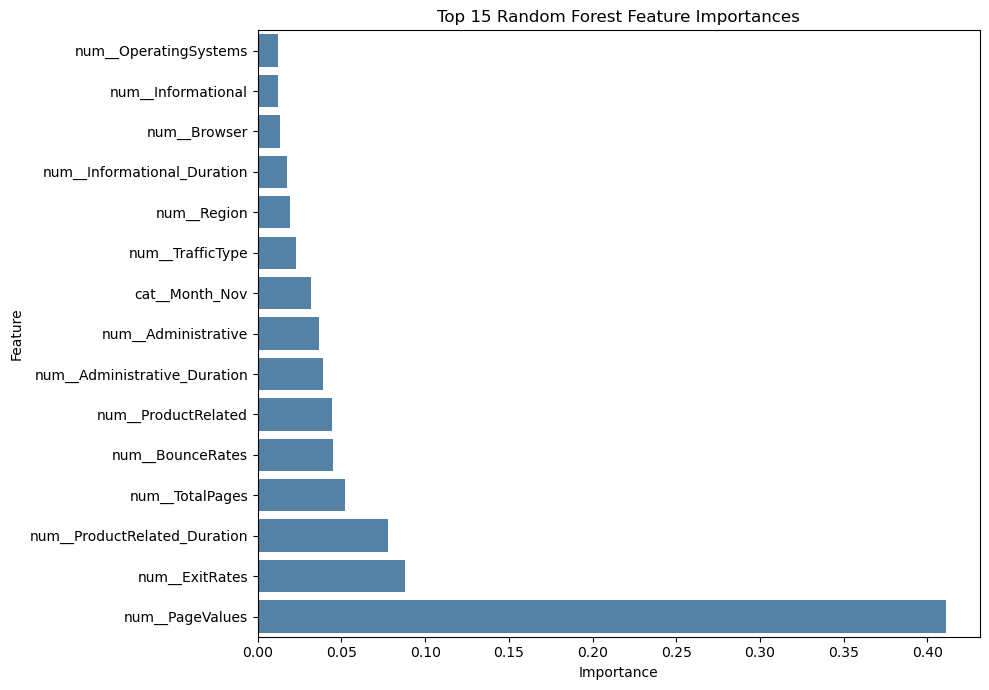

,Feature,Importance
8,num__PageValues,0.410932
7,num__ExitRates,0.087953
5,num__ProductRelated_Duration,0.077683
14,num__TotalPages,0.052392
6,num__BounceRates,0.045210
4,num__ProductRelated,0.044497
1,num__Administrative_Duration,0.039015
0,num__Administrative,0.036863
22,cat__Month_Nov,0.031883
13,num__TrafficType,0.022763


In [ ]:
rf_pipeline = review2_trained["Random Forest"]
rf_classifier = rf_pipeline.named_steps["classifier"]
rf_feature_names = rf_pipeline.named_steps["preprocessor"].get_feature_names_out()

rf_importance = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_classifier.feature_importances_
}).sort_values("Importance", ascending=False)

top_rf_importance = rf_importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
sns.barplot(
    data=top_rf_importance,
    x="Importance",
    y="Feature",
    color="steelblue"
)
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

top_rf_importance.sort_values("Importance", ascending=False)